In [34]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [35]:
df = pd.read_csv("Student_Performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [37]:
df.isnull().sum()


Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [38]:
for i in ["Hours Studied", "Sleep Hours", "Sample Question Papers Practiced"]:
    print(i,":", df[i].unique())

Hours Studied : [7 4 8 5 3 6 2 1 9]
Sleep Hours : [9 4 7 5 8 6]
Sample Question Papers Practiced : [1 2 5 6 0 8 3 4 9 7]


DATA ANALYSIS 


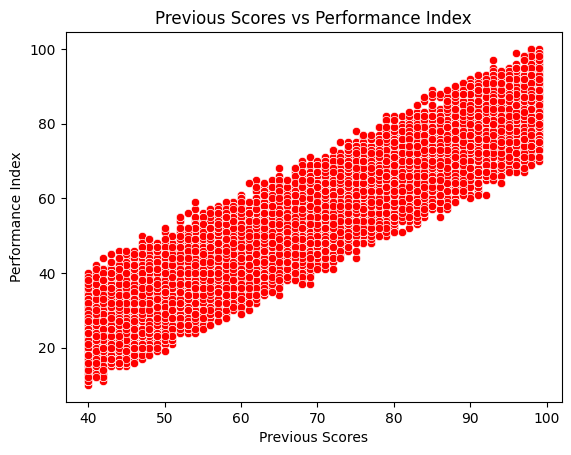

In [39]:
sns.scatterplot(x="Previous Scores",y="Performance Index",color="Red",data=df)
plt.title("Previous Scores vs Performance Index")
plt.show()

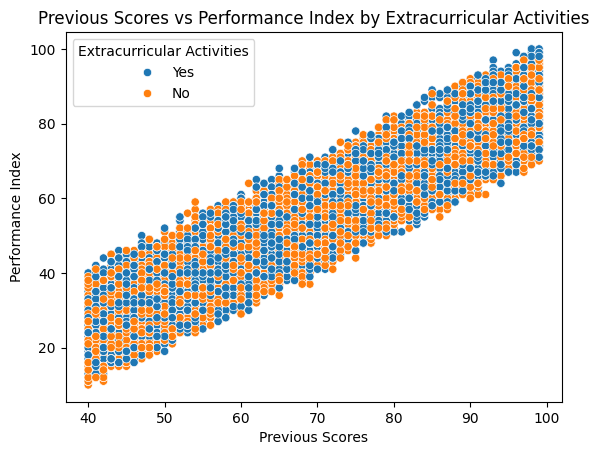

In [40]:
sns.scatterplot(x="Previous Scores",y="Performance Index",hue="Extracurricular Activities",color="Blue",data=df)
plt.title("Previous Scores vs Performance Index by Extracurricular Activities")
plt.show()

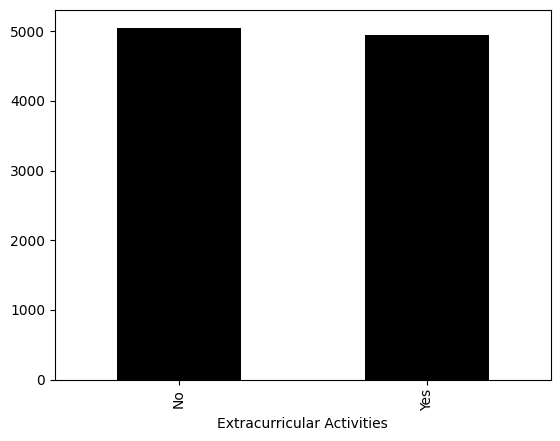

Extracurricular Activities
No     5052
Yes    4948
Name: count, dtype: int64


In [41]:
df["Extracurricular Activities"].value_counts().plot(kind="bar",color="black")
plt.show()
print(df["Extracurricular Activities"].value_counts())

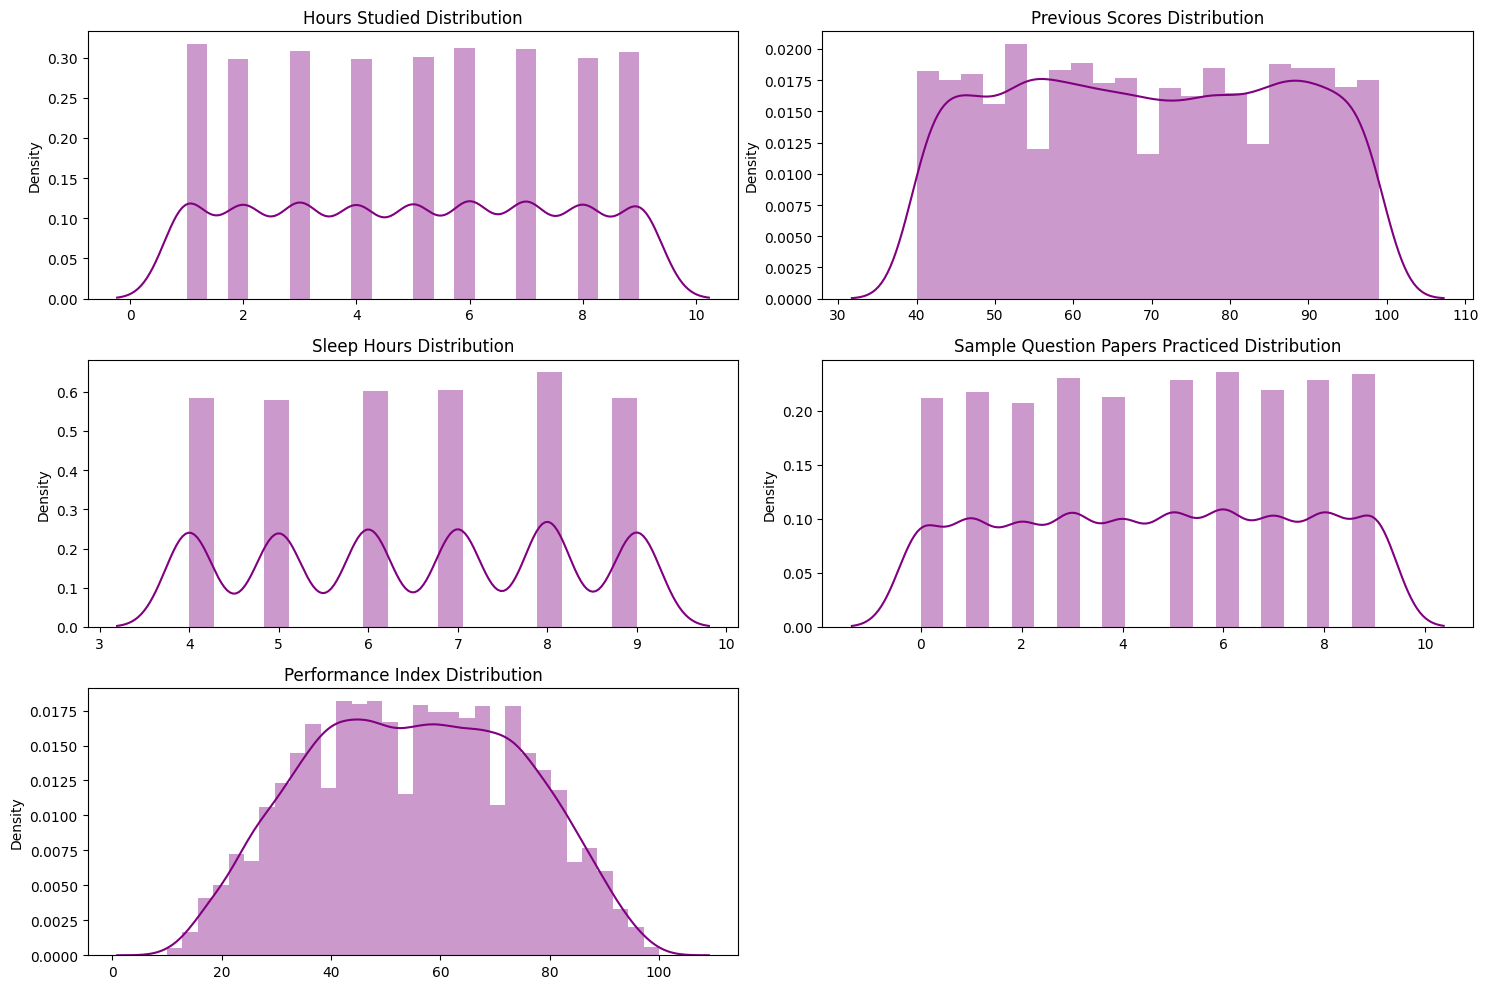

In [44]:
plt.figure(figsize=(15,10))
for i,col in enumerate(["Hours Studied","Previous Scores","Sleep Hours","Sample Question Papers Practiced","Performance Index"]):
    plt.subplot(3,2,i+1)
    sns.distplot(df[col],color="purple")
    plt.title(f"{col} Distribution")
    plt.xlabel("")
plt.tight_layout()
plt.show()

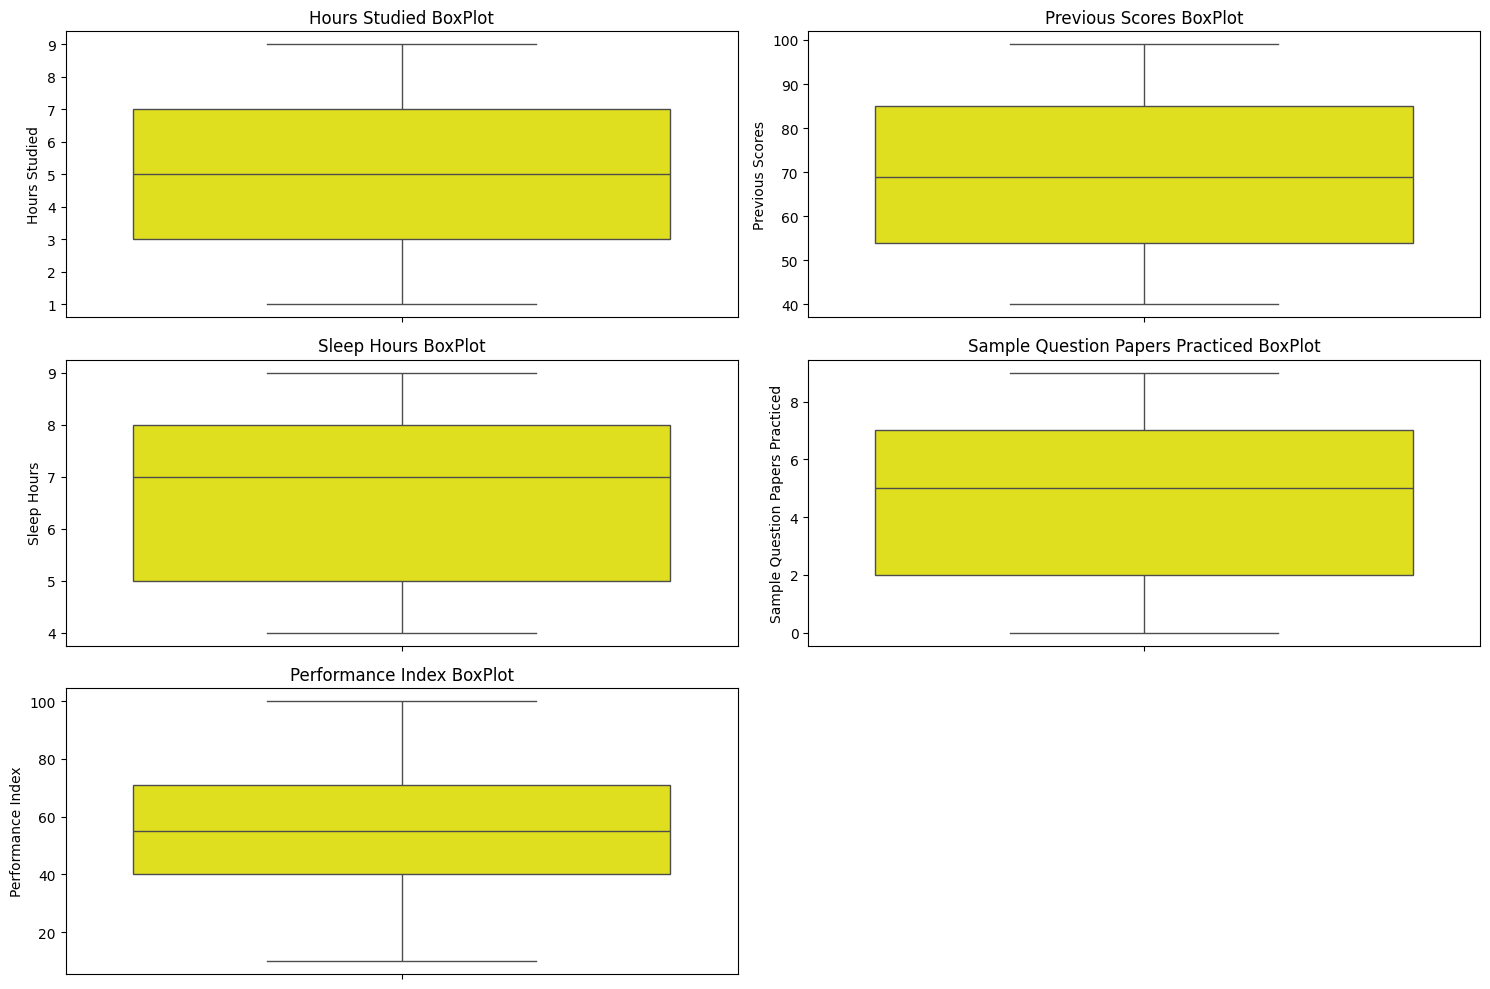

In [45]:
plt.figure(figsize=(15,10))
for i,col in enumerate(["Hours Studied","Previous Scores","Sleep Hours","Sample Question Papers Practiced","Performance Index"]):
    plt.subplot(3,2,i+1)
    sns.boxplot(df[col],color="yellow")
    plt.title(f"{col} BoxPlot")
    plt.xlabel("")
plt.tight_layout()
plt.show()

Separation of DATASET


In [46]:
from sklearn.model_selection import train_test_split

X = df.drop("Performance Index",axis=1)
y = df["Performance Index"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=42)
print((f"X train shape : {X_train.shape}"))
print(f"X test shape : {X_test.shape}")
print(f"Y train shape : {y_train.shape}")

X train shape : (7500, 5)
X test shape : (2500, 5)
Y train shape : (7500,)


 MAPPING Extracurricular Activities

In [47]:
X_train["Extracurricular Activities"] = X_train["Extracurricular Activities"].map({"Yes":1,"No":0})
X_test["Extracurricular Activities"] = X_test["Extracurricular Activities"].map({"Yes":1,"No":0})
print(X_train["Extracurricular Activities"].unique())
print(X_test["Extracurricular Activities"].unique())

[0 1]
[0 1]


In [48]:
X_train.head()


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced
4901,5,49,0,5,5
4375,7,88,1,4,9
6698,3,94,1,7,1
9805,9,54,1,5,9
1101,4,56,1,8,6


In [49]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [52]:
def calculate_model_metrics(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

MODEL TRAINING

In [53]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "ElasticNet Regression": ElasticNet(),
    "KNN Regressor": KNeighborsRegressor(),
    "Decision Tree Regressor": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor()
}

MODEL TESTING

In [54]:
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae, model_train_rmse, model_train_r2 = calculate_model_metrics(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = calculate_model_metrics(y_test, y_test_pred)

    print(list(models.values())[i]) 
    
    print("RMSE :", model_test_rmse)
    print("Mean Absolute Error :", model_test_mae)
    print("R2 Score :", model_test_r2)

    print("-----------------------------")

LinearRegression()
RMSE : 2.008119571992444
Mean Absolute Error : 1.5975792091646108
R2 Score : 0.9890550757439104
-----------------------------
Ridge()
RMSE : 2.0081238202509857
Mean Absolute Error : 1.5975800205432158
R2 Score : 0.9890550294349975
-----------------------------
Lasso()
RMSE : 2.1954630374044104
Mean Absolute Error : 1.735894295901939
R2 Score : 0.9869176464437092
-----------------------------
ElasticNet()
RMSE : 2.191145542692895
Mean Absolute Error : 1.7293004357445942
R2 Score : 0.9869690501366244
-----------------------------
KNeighborsRegressor()
RMSE : 2.4317006394702454
Mean Absolute Error : 1.9412
R2 Score : 0.9839507833228293
-----------------------------
DecisionTreeRegressor()
RMSE : 2.9709893600916475
Mean Absolute Error : 2.3410666666666664
R2 Score : 0.9760428134095308
-----------------------------
RandomForestRegressor()
RMSE : 2.269073176811209
Mean Absolute Error : 1.8150265968253967
R2 Score : 0.9860256818556753
-----------------------------
